### Dataset 
[Copernicus CEMS Fire Historical Dataset](https://ewds.climate.copernicus.eu/datasets/cems-fire-historical-v1?tab=overview)
### Coordinates Feature

| Column Name | Type | Description | Range in your file |
| :--- | :--- | :--- | :--- |
| `valid_time` | `datetime64[ns]` | Daily observation timestamp (459 days total: 153 days/year for May–Sept) | `2018-05-01` to `2023-09-30` |
| `latitude` | `float64` | Grid latitude at 0.25° resolution (51 grid steps) | 48.0° N to 60.5° N |
| `longitude` | `float64` | Grid longitude at 0.25° resolution (103 grid steps, in 0–360° format where 220.5° = -139.5° W and 246.0° = -114.0° W) | 220.5° E to 246.0° E (-139.5° W to -114.0° W) |
| `surface` | `float64` | Constant GRIB surface level indicator (0.0) | `0.0` |

### Fire Weather Index Features (7 Data Variables)
| NetCDF Variable (`shortName`) | Type | Full Name & What It Measures | Possible Values / Danger Class Thresholds (Canadian / EFFIS Standard) |
| :--- | :--- | :--- | :--- |
| `ffmcode` | `float64` | **Fine Fuel Moisture Code:** Moisture content of surface litter and cured fine fuels (top 1–2 cm); indicates ease of ignition and flammability. | **Continuous (0–101 scale)**<br>• Low: 0–80<br>• Moderate: 81–85<br>• High: 86–88<br>• Very High: 89–91<br>• Extreme: 92+ |
| `dufmcode` | `float64` | **Duff Moisture Code:** Moisture content of loosely compacted organic layers of moderate depth (5–10 cm); indicates fuel consumption in medium-sized woody material. | **Continuous (0 to open-ended, typically < 300)**<br>• Low: 0–15<br>• Moderate: 16–30<br>• High: 31–50<br>• Very High: 51–75<br>• Extreme: 75+ |
| `drtcode` | `float64` | **Drought Code:** Moisture content of deep, compact organic layers (10–20 cm); tracks seasonal drought effects on heavy forest fuels and smoldering potential. | **Continuous (0 to open-ended, typically < 1000)**<br>• Low: 0–100<br>• Moderate: 101–250<br>• High: 251–350<br>• Very High: 351–500<br>• Extreme: 500+ |
| `infsinx` | `float64` | **Initial Spread Index:** Combines wind speed and FFMC to estimate the expected rate of fire spread without the influence of variable fuel quantities. | **Continuous (0 to open-ended, typically < 50)**<br>• Low: 0–2<br>• Moderate: 3–5<br>• High: 6–10<br>• Very High: 11–16<br>• Extreme: 16+ |
| `fbupinx` | `float64` | **Buildup Index:** Combines DMC and DC to indicate the total amount of fuel available for combustion. | **Continuous (0 to open-ended, typically < 300)**<br>• Low: 0–20<br>• Moderate: 21–40<br>• High: 41–60<br>• Very High: 61–90<br>• Extreme: 90+ |
| `fwinx` | `float64` | **Forest Fire Weather Index:** Combines ISI and BUI into a single numerical rating of overall frontal fire intensity (general fire danger). | **Continuous (0 to open-ended, typically < 100)**<br>• Very Low: < 5.2<br>• Low: 5.2–11.2<br>• Moderate: 11.2–21.3<br>• High: 21.3–38.0<br>• Very High: 38.0–50.0<br>• Extreme: ≥ 50.0 |
| `fdsrte` | `float64` | **Fire Daily Severity Rating:** A power transformation of FWI reflecting the difficulty of controlling fires across extreme values. | **Continuous (0 to open-ended, DSR = 0.0272 × FWI^1.77)**<br>• Low: < 1<br>• Moderate: 1–3<br>• High: 3–7<br>• Very High: 7–15<br>• Extreme: 15+ |

In [8]:
import pandas as pd

# 1. Open the CSV file with pandas
df = pd.read_csv("../datasets/dataset_CEMS_18_24.csv")

# Convert valid_time to datetime
df['valid_time'] = pd.to_datetime(df['valid_time'])

# 2. Check the combined results
print(f"Total Rows:    {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
print(f"Date Range:    {df['valid_time'].min().date()} to {df['valid_time'].max().date()}")

# 3. Rows by Year
df['year'] = df['valid_time'].dt.year
print("\nRows by Year:")
print(df['year'].value_counts().sort_index())

Total Rows:    2,438,667
Total Columns: 13
Date Range:    2018-05-01 to 2024-09-30

Rows by Year:
year
2018    348381
2019    348381
2020    348381
2021    348381
2022    348381
2023    348381
2024    348381
Name: count, dtype: int64


In [9]:
# 1. Count null (NaN) values per column and calculate the percentage
null_counts = df.isnull().sum()
null_percentages = (df.isnull().sum() / len(df)) * 100

null_summary = pd.DataFrame({
    'Null Count': null_counts,
    'Percentage (%)': null_percentages.round(2)
})

print("=== Null (Missing) Values per Column ===")
display(null_summary)

=== Null (Missing) Values per Column ===


,Null Count,Percentage (%)
valid_time,0,0.0
latitude,0,0.0
longitude,0,0.0
fbupinx,0,0.0
drtcode,0,0.0
dufmcode,0,0.0
ffmcode,0,0.0
fdsrte,0,0.0
fwinx,0,0.0
infsinx,0,0.0


In [12]:
# 2. Count zero values (col == 0) per column and calculate the percentage
zero_counts = (df == 0).sum()
zero_percentages = ((df == 0).sum() / len(df)) * 100

zero_summary = pd.DataFrame({
    'Zero Count': zero_counts,
    'Percentage (%)': zero_percentages.round(2)
})

print("=== Exact Zero (0) Values per Column ===")
display(zero_summary)

=== Exact Zero (0) Values per Column ===


,Zero Count,Percentage (%)
valid_time,0,0.00
latitude,0,0.00
longitude,0,0.00
fbupinx,22495,0.47
drtcode,0,0.00
dufmcode,37218,0.77
ffmcode,0,0.00
fdsrte,0,0.00
fwinx,0,0.00
infsinx,0,0.00


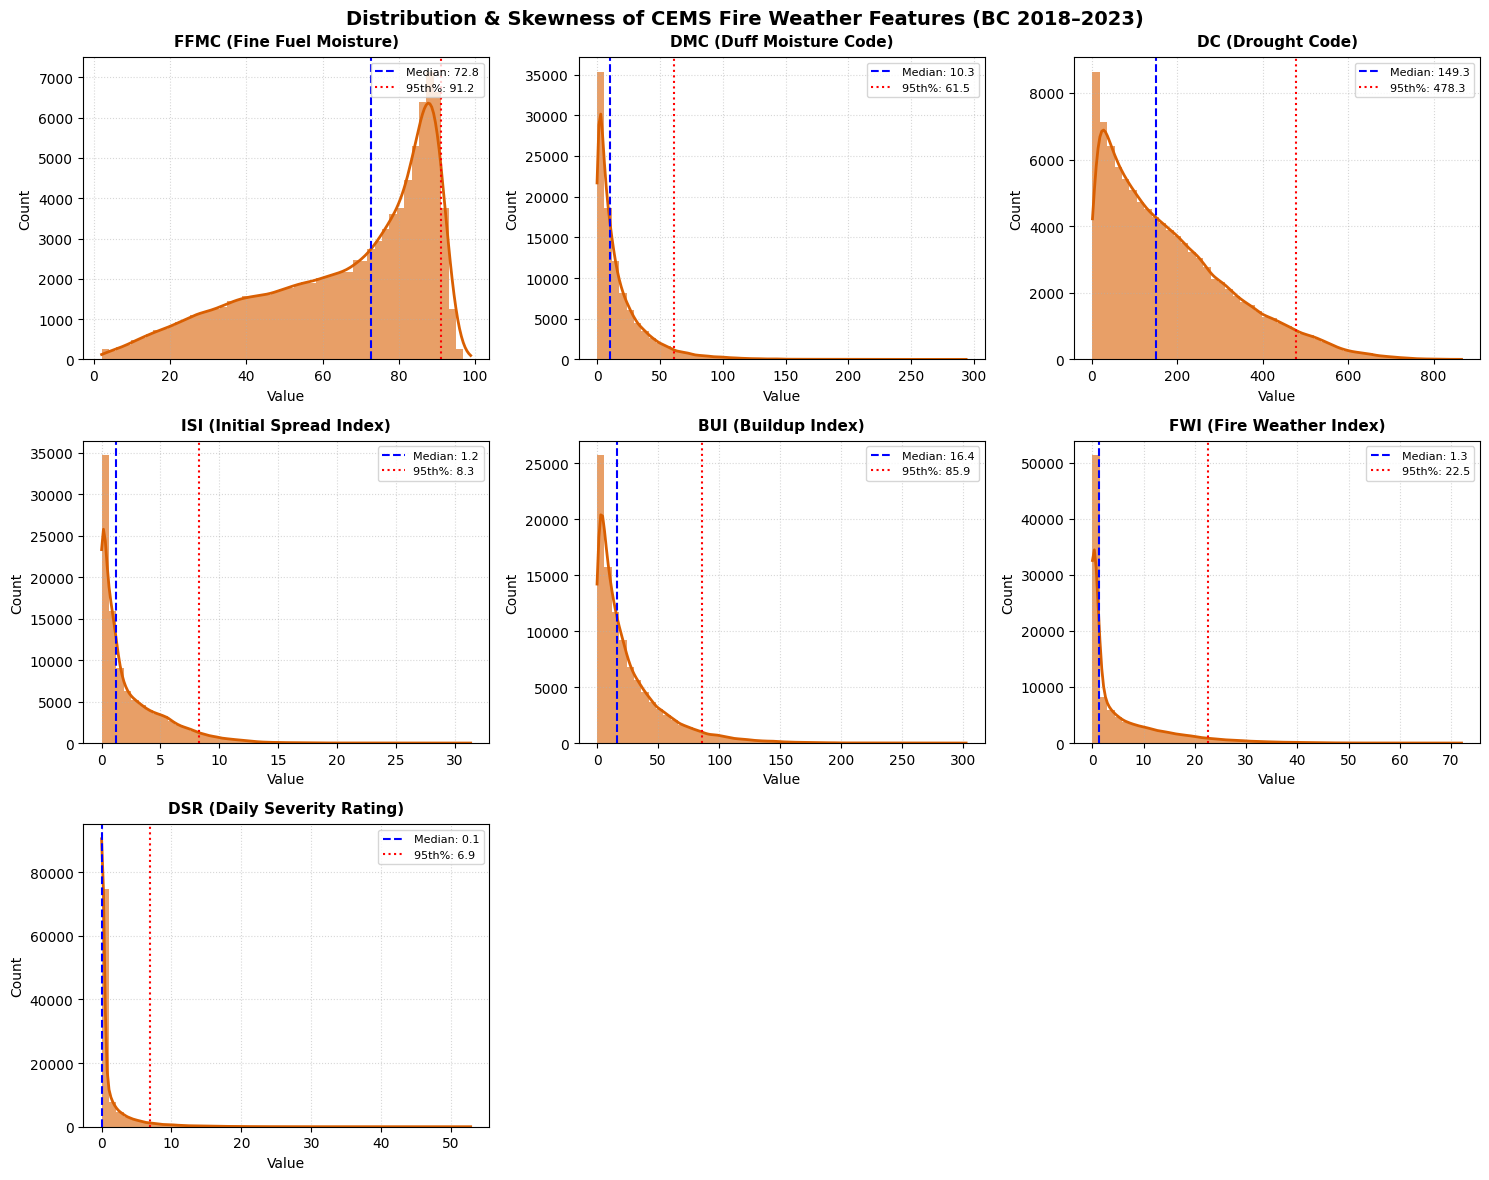

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------------------------------------
# Feature Distributions: Histograms + KDE Curves
# ---------------------------------------------------------
fwi_vars = ['ffmcode', 'dufmcode', 'drtcode', 'infsinx', 'fbupinx', 'fwinx', 'fdsrte']
var_titles = [
    'FFMC (Fine Fuel Moisture)',
    'DMC (Duff Moisture Code)',
    'DC (Drought Code)',
    'ISI (Initial Spread Index)',
    'BUI (Buildup Index)',
    'FWI (Fire Weather Index)',
    'DSR (Daily Severity Rating)'
]

# Sample 100,000 rows for smooth, fast KDE plotting
sample_df = df[fwi_vars].sample(n=min(100000, len(df)), random_state=42)

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

# Distinct fire palette color
bar_color = '#d95f02'

for i, var in enumerate(fwi_vars):
    ax = axes[i]
    
    # Plot Histogram + KDE curve
    sns.histplot(
        sample_df[var], 
        kde=True, 
        bins=50, 
        color=bar_color, 
        edgecolor=None, 
        alpha=0.6, 
        line_kws={'linewidth': 2, 'color': '#7f2704'},
        ax=ax
    )
    
    # Add vertical reference lines: Median (50%) and 95th Percentile
    median_val = df[var].median()
    p95_val = df[var].quantile(0.95)
    
    ax.axvline(median_val, color='blue', linestyle='--', linewidth=1.5, label=f'Median: {median_val:.1f}')
    ax.axvline(p95_val, color='red', linestyle=':', linewidth=1.5, label=f'95th%: {p95_val:.1f}')
    
    ax.set_title(var_titles[i], fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.5)

# Hide the unused 8th and 9th subplots in the 3x3 grid
axes[7].set_visible(False)
axes[8].set_visible(False)

fig.suptitle('Distribution & Skewness of CEMS Fire Weather Features (BC 2018–2023)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

=== 1. Numeric Percentiles & Skewness ===


,mean,std,50%,95%,max,skewness
ffmcode,65.80,22.81,72.75,91.13,99.15,-0.78
dufmcode,18.02,22.20,10.20,62.62,300.63,2.56
drtcode,180.52,147.19,145.07,474.24,903.12,1.00
infsinx,2.37,2.83,1.22,8.19,36.12,1.77
fbupinx,26.22,29.32,16.19,87.22,306.45,2.06
fwinx,5.25,7.92,1.27,22.47,72.05,2.15
fdsrte,1.26,2.94,0.05,6.84,52.81,4.24


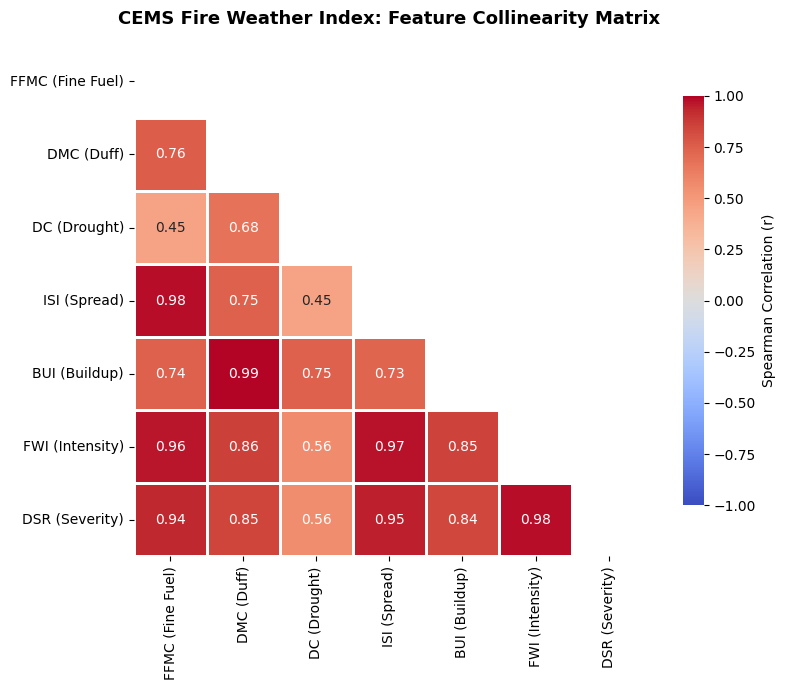

=== Highly Correlated Pairs (|r| >= 0.85) ===


,Feature 1,Feature 2,Spearman r
0,ffmcode,infsinx,0.982
1,ffmcode,fwinx,0.965
2,ffmcode,fdsrte,0.936
3,dufmcode,fbupinx,0.993
4,dufmcode,fwinx,0.863
5,infsinx,fwinx,0.974
6,infsinx,fdsrte,0.948
7,fbupinx,fwinx,0.852
8,fwinx,fdsrte,0.978


In [ ]:
import seaborn as sns

# ---------------------------------------------------------
# 1. Statistical Summary: Percentiles & Skewness
# ---------------------------------------------------------
fwi_vars = ['ffmcode', 'dufmcode', 'drtcode', 'infsinx', 'fbupinx', 'fwinx', 'fdsrte']
var_labels = ['FFMC (Fine Fuel)', 'DMC (Duff)', 'DC (Drought)', 'ISI (Spread)', 'BUI (Buildup)', 'FWI (Intensity)', 'DSR (Severity)']

print("=== 1. Numeric Percentiles & Skewness ===")
summary = df[fwi_vars].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
summary['skewness'] = df[fwi_vars].skew()
display(summary[['mean', 'std', '50%', '95%', 'max', 'skewness']].round(2))

# ---------------------------------------------------------
# 2. Spearman Correlation & Collinearity Matrix
# ---------------------------------------------------------
corr_matrix = df[fwi_vars].corr(method='spearman')

fig, ax = plt.subplots(figsize=(9, 7))

# Mask the upper triangle for clean triangular view
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1,
    square=True, 
    linewidths=0.8, 
    cbar_kws={"shrink": 0.8, "label": "Spearman Correlation (r)"},
    xticklabels=var_labels,
    yticklabels=var_labels,
    ax=ax
)

ax.set_title("CEMS Fire Weather Index: Feature Collinearity Matrix", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Highlight Highly Correlated Redundant Pairs (|r| >= 0.85)
# ---------------------------------------------------------
print("=== Highly Correlated Pairs (|r| >= 0.85) ===")
high_corr = []
for i in range(len(fwi_vars)):
    for j in range(i + 1, len(fwi_vars)):
        val = corr_matrix.iloc[i, j]
        if abs(val) >= 0.85:
            high_corr.append({'Feature 1': fwi_vars[i], 'Feature 2': fwi_vars[j], 'Spearman r': round(val, 3)})

display(pd.DataFrame(high_corr))

/var/folders/w6/rpdn466908l5tjpr9vzp0vpc0000gn/T/ipykernel_20311/746887387.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/w6/rpdn466908l5tjpr9vzp0vpc0000gn/T/ipykernel_20311/746887387.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/w6/rpdn466908l5tjpr9vzp0vpc0000gn/T/ipykernel_20311/746887387.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/w6/rpdn466908l5tjpr9vzp0vpc0000gn/T/ipykernel_20311/746887387.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

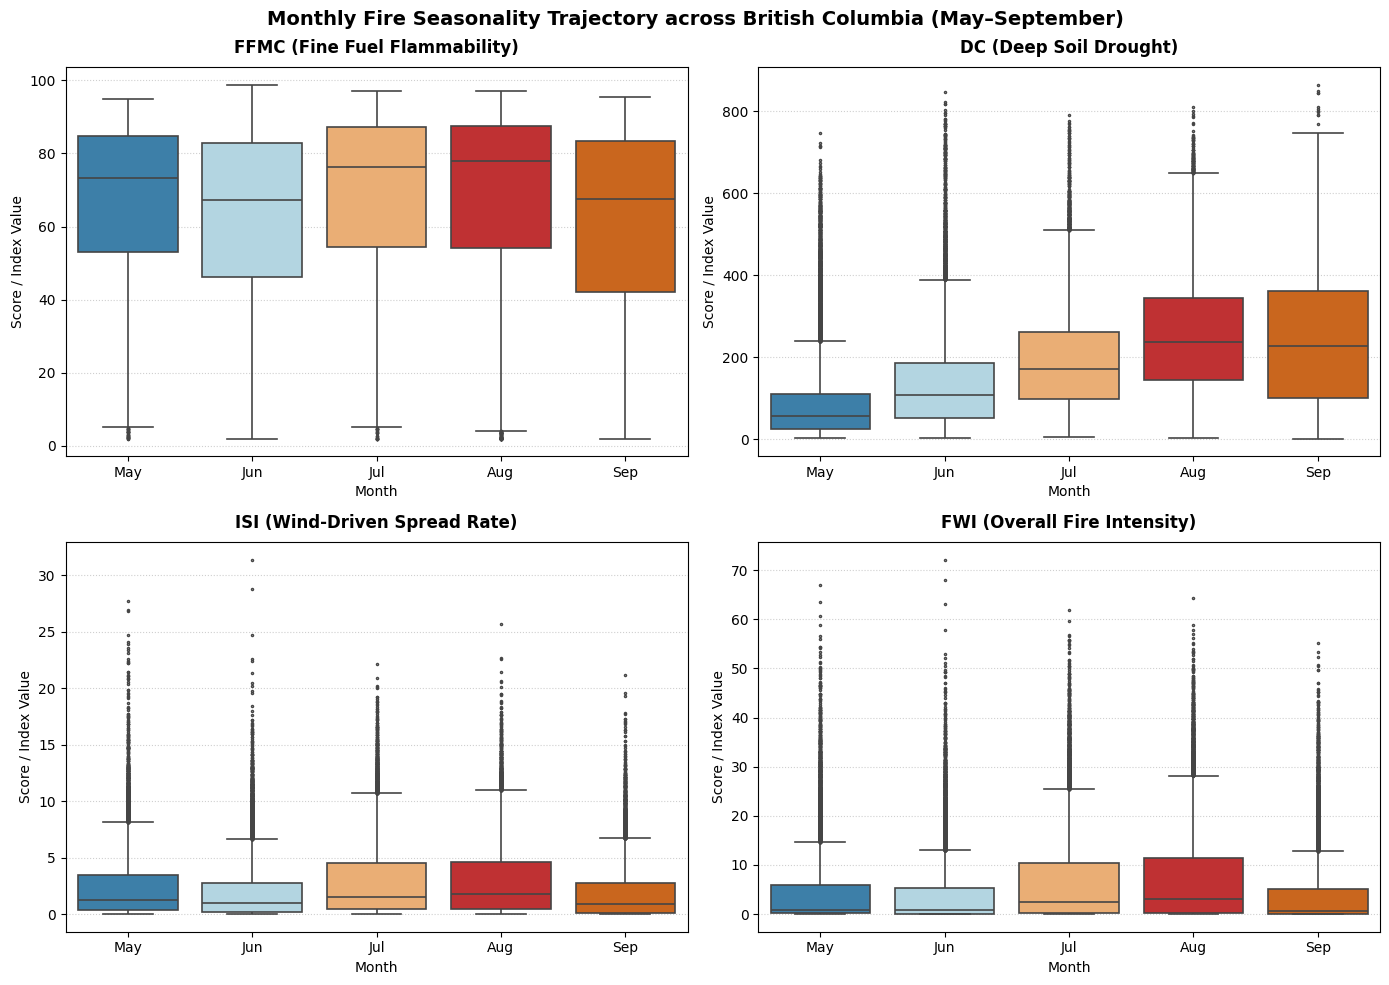

=== Monthly Medians across BC Fire Season ===


,ffmcode,drtcode,infsinx,fwinx
month_name,,,,
May,73.08,56.16,1.21,0.91
Jun,67.28,106.68,0.94,0.74
Jul,76.58,172.71,1.58,2.43
Aug,77.74,236.35,1.77,3.13
Sep,67.76,229.58,0.93,0.67


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ---------------------------------------------------------
# 1. Prepare Month Names
# ---------------------------------------------------------
df['month'] = pd.to_datetime(df['valid_time']).dt.month
month_map = {5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep'}
df['month_name'] = df['month'].map(month_map)

# Focus on your 4 selected features
selected_4 = ['ffmcode', 'drtcode', 'infsinx', 'fwinx']
titles_4 = [
    'FFMC (Fine Fuel Flammability)', 
    'DC (Deep Soil Drought)', 
    'ISI (Wind-Driven Spread Rate)', 
    'FWI (Overall Fire Intensity)'
]

# Sample 100,000 rows for fast, clean boxplots
sample_df = df[['month_name', 'year'] + selected_4].sample(n=min(100000, len(df)), random_state=42)
month_order = ['May', 'Jun', 'Jul', 'Aug', 'Sep']

# ---------------------------------------------------------
# 2. Plot: Monthly Boxplots for the 4 Core Features
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

palette = ['#2b83ba', '#abd9e9', '#fdae61', '#d7191c', '#e66101']

for i, col in enumerate(selected_4):
    ax = axes[i]
    
    # Monthly Boxplot
    sns.boxplot(
        data=sample_df, 
        x='month_name', 
        y=col, 
        order=month_order,
        palette=palette,
        fliersize=1.5,
        linewidth=1.2,
        ax=ax
    )
    
    ax.set_title(titles_4[i], fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Month', fontsize=10)
    ax.set_ylabel('Score / Index Value', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6, axis='y')

fig.suptitle('Monthly Fire Seasonality Trajectory across British Columbia (May–September)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Monthly Median Progression Table
# ---------------------------------------------------------
print("=== Monthly Medians across BC Fire Season ===")
monthly_medians = df.groupby('month_name')[selected_4].median().reindex(month_order)
display(monthly_medians.round(2))

=== Percentage of High/Extreme Danger Observations by Year ===


danger_class,Low / Very Low,Moderate,High,Extreme
year,,,,
2018,77.47,14.35,7.47,0.70
2019,88.91,8.36,2.52,0.22
2020,91.61,5.96,2.04,0.39
2021,81.46,11.55,5.92,1.07
2022,82.35,12.40,4.83,0.42
2023,74.79,16.35,7.90,0.96


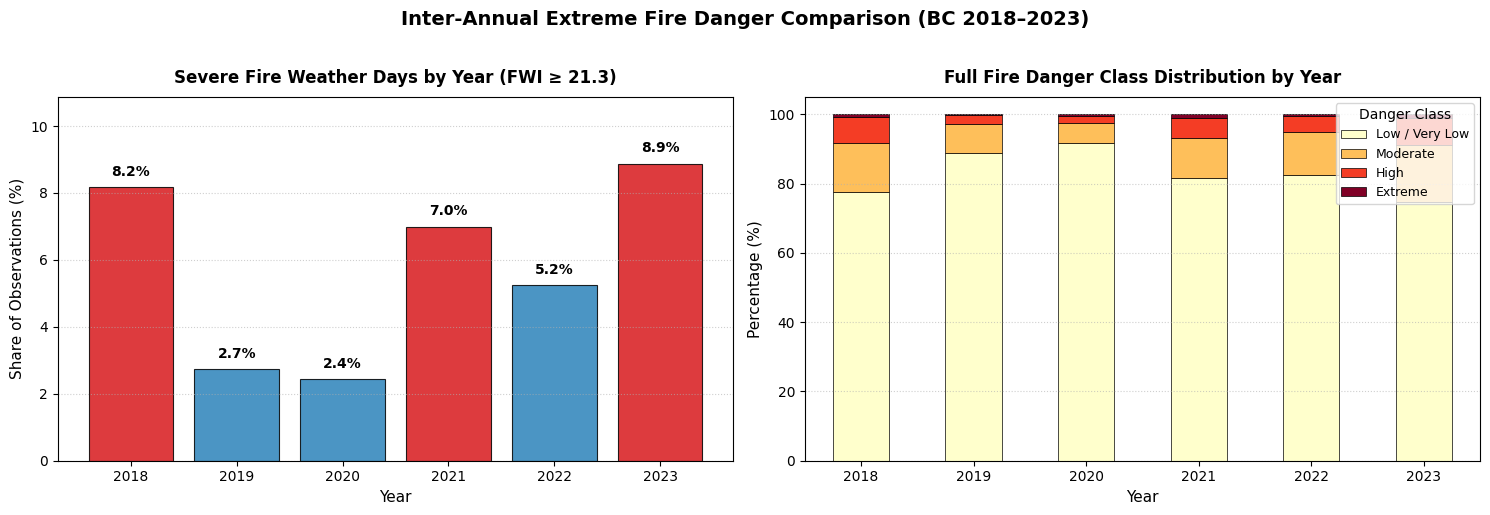

In [6]:
# ---------------------------------------------------------
# 1. Categorize into Canadian Forest Service FWI Danger Classes
# ---------------------------------------------------------
# Standard Canadian / EFFIS Danger Thresholds
# Low: < 11.2 | Moderate: 11.2 - 21.3 | High: 21.3 - 38.0 | Extreme: >= 38.0
bins = [-np.inf, 11.2, 21.3, 38.0, np.inf]
labels = ['Low / Very Low', 'Moderate', 'High', 'Extreme']
df['danger_class'] = pd.cut(df['fwinx'], bins=bins, labels=labels)

# ---------------------------------------------------------
# 2. Calculate % of High & Extreme Fire Weather Days per Year
# ---------------------------------------------------------
annual_danger = pd.crosstab(df['year'], df['danger_class'], normalize='index') * 100
annual_high_extreme = (annual_danger['High'] + annual_danger['Extreme']).round(2)

print("=== Percentage of High/Extreme Danger Observations by Year ===")
display(annual_danger.round(2))

# ---------------------------------------------------------
# 3. Plot: Annual Extremes Bar Chart
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot A: % of Days in High or Extreme Danger (FWI >= 21.3)
colors = ['#d7191c' if yr in [2018, 2021, 2023] else '#2b83ba' for yr in annual_high_extreme.index]
bars = ax1.bar(annual_high_extreme.index.astype(str), annual_high_extreme.values, color=colors, alpha=0.85, edgecolor='black', linewidth=0.8)

ax1.set_title("Severe Fire Weather Days by Year (FWI ≥ 21.3)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Year", fontsize=11)
ax1.set_ylabel("Share of Observations (%)", fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6, axis='y')
ax1.set_ylim(0, max(annual_high_extreme.values) + 2)

# Add text labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.25, f'{height:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot B: Stacked Bar Chart of All Danger Classes
annual_danger[['Low / Very Low', 'Moderate', 'High', 'Extreme']].plot(
    kind='bar',
    stacked=True,
    colormap='YlOrRd',
    edgecolor='black',
    linewidth=0.5,
    ax=ax2
)

ax2.set_title("Full Fire Danger Class Distribution by Year", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Year", fontsize=11)
ax2.set_ylabel("Percentage (%)", fontsize=11)
ax2.tick_params(axis='x', rotation=0)
ax2.legend(title="Danger Class", fontsize=9, loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6, axis='y')

fig.suptitle('Inter-Annual Extreme Fire Danger Comparison (BC 2018–2023)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

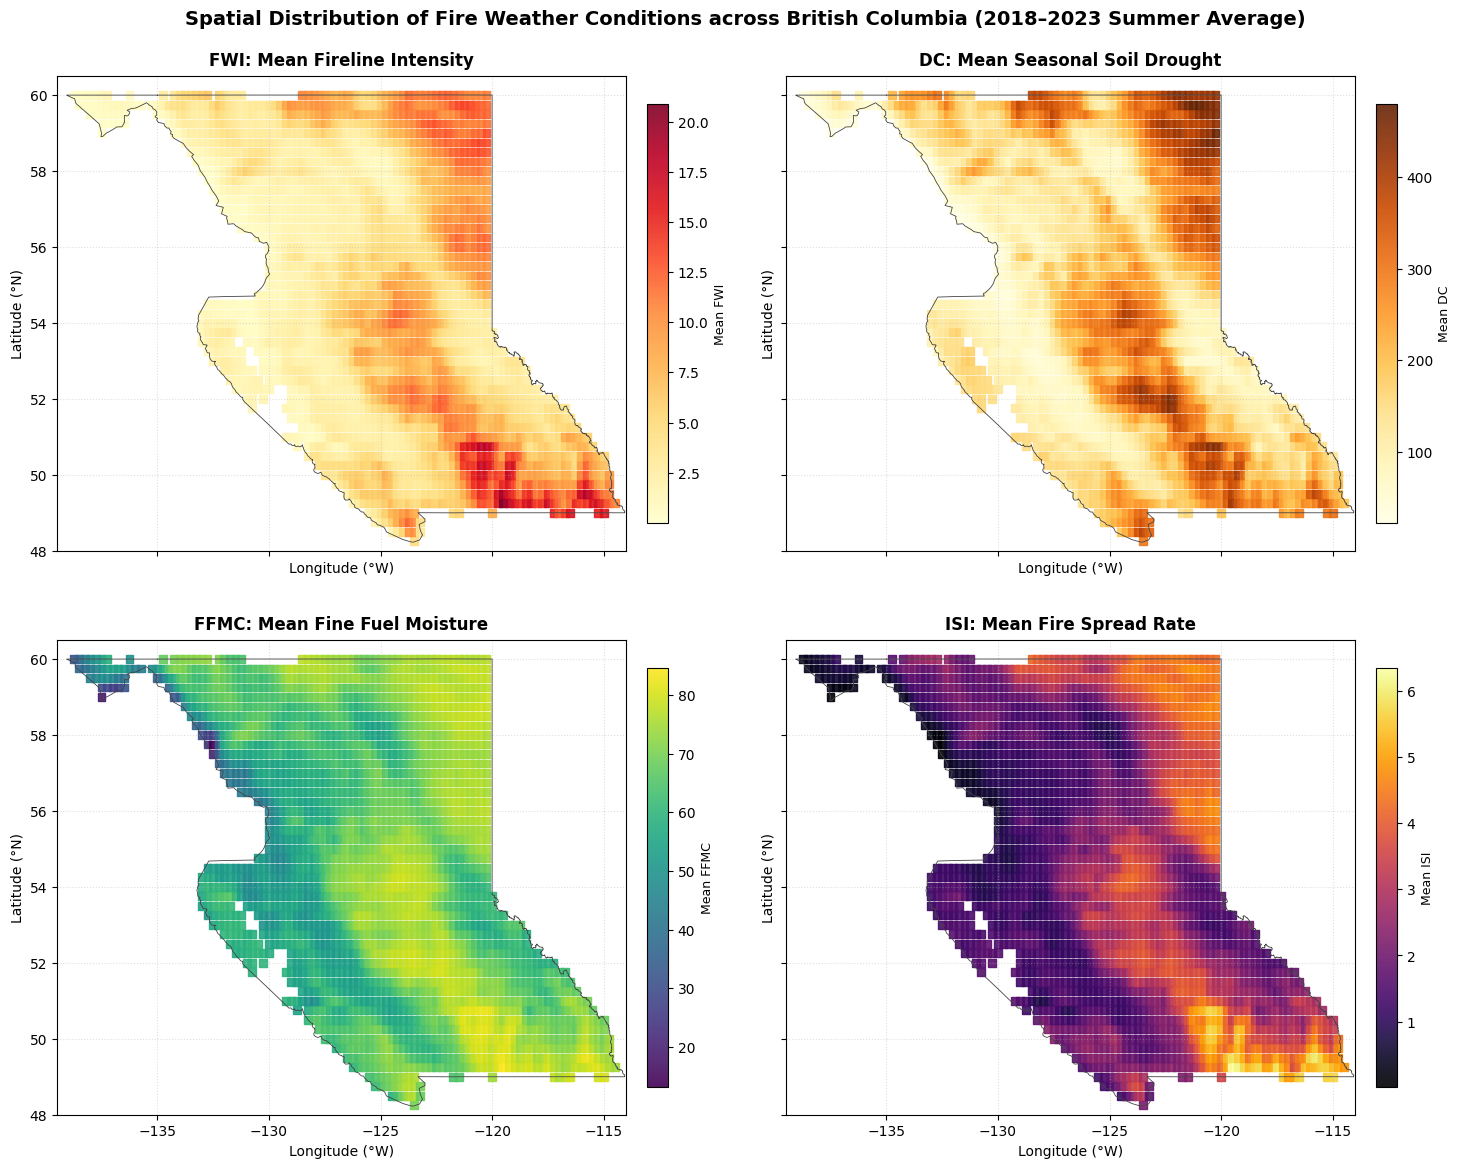

In [12]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import shape

# ---------------------------------------------------------
# 1. Load BC Legal Boundary for Map Outline
# ---------------------------------------------------------
boundary_file = Path("../datasets/bc_legal_boundary.geojson")
if not boundary_file.exists():
    boundary_file = Path("datasets/bc_legal_boundary.geojson")

bc_polygons = []
if boundary_file.exists():
    b_data = json.loads(boundary_file.read_text(encoding="utf-8"))
    for f in b_data["features"]:
        geom = shape(f["geometry"])
        if geom.geom_type == "MultiPolygon":
            bc_polygons.extend(geom.geoms)
        else:
            bc_polygons.append(geom)

# ---------------------------------------------------------
# 2. Compute Mean Summer Values for Each Unique Grid Cell
# ---------------------------------------------------------
# CEMS uses longitude_deg (or standardizes if needed)
lon_col = 'longitude_deg' if 'longitude_deg' in df.columns else 'longitude'
if df[lon_col].min() > 0:
    df['longitude_deg'] = ((df[lon_col] + 180) % 360) - 180
    lon_col = 'longitude_deg'

grid_means = df.groupby(['latitude', lon_col])[['fwinx', 'drtcode', 'ffmcode', 'infsinx']].mean().reset_index()

# ---------------------------------------------------------
# 3. Plot 4 Provincial Heatmaps (Aspect-Ratio Corrected)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 12), sharex=True, sharey=True)
axes = axes.flatten()

maps_config = [
    ('fwinx', 'FWI: Mean Fireline Intensity', 'YlOrRd', 'Mean FWI'),
    ('drtcode', 'DC: Mean Seasonal Soil Drought', 'YlOrBr', 'Mean DC'),
    ('ffmcode', 'FFMC: Mean Fine Fuel Moisture', 'viridis', 'Mean FFMC'),
    ('infsinx', 'ISI: Mean Fire Spread Rate', 'inferno', 'Mean ISI')
]

# Standard BC map aspect ratio at ~54°N latitude
bc_aspect = 1 / np.cos(np.deg2rad(54))

for i, (col, title, cmap, label) in enumerate(maps_config):
    ax = axes[i]
    
    # Draw BC border outline
    for poly in bc_polygons:
        x, y = poly.exterior.xy
        ax.plot(x, y, color='#444444', linewidth=0.6, zorder=2)
        
    # Scatter 2D Heatmap of grid cells
    sc = ax.scatter(
        grid_means[lon_col],
        grid_means['latitude'],
        c=grid_means[col],
        cmap=cmap,
        s=32,
        marker='s', # square grid cells
        alpha=0.9,
        zorder=1
    )
    
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel('Longitude (°W)', fontsize=10)
    ax.set_ylabel('Latitude (°N)', fontsize=10)
    ax.set_xlim(-139.5, -114.0)
    ax.set_ylim(48.0, 60.5)
    ax.set_aspect(bc_aspect)
    ax.grid(True, linestyle=':', alpha=0.4)
    
    # Colorbar
    cbar = plt.colorbar(sc, ax=ax, shrink=0.75, pad=0.03)
    cbar.set_label(label, fontsize=9)

fig.suptitle('Spatial Distribution of Fire Weather Conditions across British Columbia (2018–2023 Summer Average)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()